<div align="center">

# RANCANGAN DAN EKSEKUSI PROMPT RTCIK-OQV


Mata Kuliah: **Kecerdasan Artifisial untuk Geofisika**

Nama: Muh. Tenri Kahfi GP  
NIM: H061241084

</div>

---

## 1. Rancangan Kerja dan Definisi Data

### Alur analisis

**Pilih metode → tetapkan peran dan tugas → jelaskan konteks dan input → batasi klaim → proses data → hasilkan output → periksa kualitas.**

| Komponen | Pertanyaan yang dijawab |
|---|---|
| **R — Role** | Keahlian apa yang harus digunakan AI? |
| **T — Task** | Analisis apa yang harus dilakukan? |
| **C — Context** | Apa latar belakang dan tujuan geofisikanya? |
| **I — Input** | Data dan parameter apa yang tersedia? |
| **K — Constraints** | Apa yang tidak boleh diasumsikan atau diklaim? |
| **O — Output** | Bentuk hasil apa yang wajib dihasilkan? |
| **Q — Quality Criteria** | Bagaimana mutu hasil dinilai? |
| **V — Verification** | Pemeriksaan apa yang harus dilakukan sebelum hasil diterima? |

### Status data

Data dalam eksperimen ini **sintetis/ilustratif**, dibuat di dalam notebook agar semua sel dapat dijalankan tanpa mengunduh berkas eksternal. Data tersebut bukan hasil survei lapangan dan tidak boleh dilaporkan sebagai data pengukuran nyata. Referensi dataset nyata disediakan pada bagian akhir.

## 2. Menyiapkan Lingkungan Komputasi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(17)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 10

print("Lingkungan siap: NumPy, Pandas, Matplotlib.")

Lingkungan siap: NumPy, Pandas, Matplotlib.


# 3. Laboratorium Metode I — Geomagnetik
### Pertanyaan geofisika
Di mana pusat anomali magnetik pada grid dan bagaimana pola spasialnya?

#### Prompt RTCIK-OQV

| Elemen | Instruksi untuk AI |
|---|---|
| **R — Role** | Berperan sebagai geofisikawan eksplorasi yang memahami medan magnet bumi dan suseptibilitas batuan. |
| **T — Task** | Petakan pola anomali, tentukan nilai ekstrem, dan jelaskan interpretasi awal sumber magnetik. |
| **C — Context** | Variasi medan magnet dapat mencerminkan kontras kemagnetan batuan, tetapi sumber anomali tidak selalu unik. |
| **I — Input** | Grid koordinat X-Y dan anomali magnetik dalam nT. |
| **K — Constraints** | Tidak boleh memastikan litologi atau mineral hanya dari pola anomali; data ini sintetis. |
| **O — Output** | Peta kontur, nilai minimum/maksimum, lokasi ekstrem, dan interpretasi ringkas. |
| **Q — Quality Criteria** | Satuan dan label lengkap; nilai ekstrem dihitung dari array yang diplot. |
| **V — Verification** | Periksa nilai kosong, rentang nilai, serta kecocokan lokasi ekstrem dengan peta. |

### Input dan pemrosesan

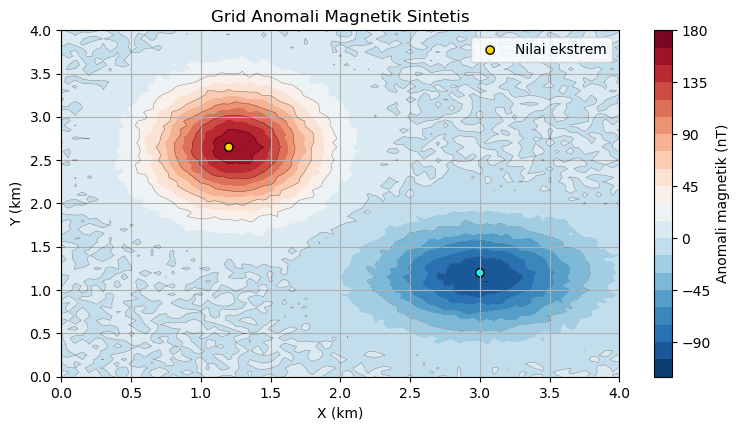

Rentang anomali: -108.16 hingga 168.32 nT
Maksimum pada X=1.20 km, Y=2.65 km
Minimum pada X=3.00 km, Y=1.20 km


In [2]:
x = np.linspace(0, 4, 81)
y = np.linspace(0, 4, 81)
X, Y = np.meshgrid(x, y)

# Anomali Gaussian ilustratif (nT), bukan data lapangan
mag = (
    165 * np.exp(-(((X - 1.25) / 0.55)**2 + ((Y - 2.65) / 0.65)**2))
    - 105 * np.exp(-(((X - 3.0) / 0.7)**2 + ((Y - 1.15) / 0.55)**2))
    + np.random.normal(0, 2.5, X.shape)
)
idx_max = np.unravel_index(np.argmax(mag), mag.shape)
idx_min = np.unravel_index(np.argmin(mag), mag.shape)
mag_min, mag_max = float(mag.min()), float(mag.max())

fig, ax = plt.subplots()
im = ax.contourf(X, Y, mag, levels=24, cmap="RdBu_r")
ax.contour(X, Y, mag, levels=10, colors="k", linewidths=0.35, alpha=0.45)
ax.scatter([X[idx_max], X[idx_min]], [Y[idx_max], Y[idx_min]],
           c=["gold", "cyan"], edgecolors="black", label="Nilai ekstrem")
ax.set(title="Grid Anomali Magnetik Sintetis", xlabel="X (km)", ylabel="Y (km)")
fig.colorbar(im, ax=ax, label="Anomali magnetik (nT)")
ax.legend()
plt.show()

print(f"Rentang anomali: {mag_min:.2f} hingga {mag_max:.2f} nT")
print(f"Maksimum pada X={X[idx_max]:.2f} km, Y={Y[idx_max]:.2f} km")
print(f"Minimum pada X={X[idx_min]:.2f} km, Y={Y[idx_min]:.2f} km")

In [3]:
print("OUTPUT 1 | GEOMAGNETIK")
print(f"Grid memperlihatkan anomali positif dan negatif dalam rentang {mag_min:.1f} sampai {mag_max:.1f} nT.")
print(f"Pusat nilai positif tertinggi berada di sekitar ({X[idx_max]:.2f}, {Y[idx_max]:.2f}) km.")
print(f"Pusat nilai negatif terendah berada di sekitar ({X[idx_min]:.2f}, {Y[idx_min]:.2f}) km.")
print("Interpretasi terbatas: model memuat dua pusat respons magnetik. Sumber geologi nyata memerlukan konteks geologi dan pemodelan.")
print("QC:", "LULUS" if np.isfinite(mag).all() else "PERIKSA DATA")

OUTPUT 1 | GEOMAGNETIK
Grid memperlihatkan anomali positif dan negatif dalam rentang -108.2 sampai 168.3 nT.
Pusat nilai positif tertinggi berada di sekitar (1.20, 2.65) km.
Pusat nilai negatif terendah berada di sekitar (3.00, 1.20) km.
Interpretasi terbatas: model memuat dua pusat respons magnetik. Sumber geologi nyata memerlukan konteks geologi dan pemodelan.
QC: LULUS


# 4. Laboratorium Metode II — Ground Penetrating Radar (GPR)
### Pertanyaan geofisika
Pada waktu tempuh berapa reflektor muncul, dan berapa kedalamannya jika kecepatan rambat diasumsikan?

#### Prompt RTCIK-OQV

| Elemen | Instruksi untuk AI |
|---|---|
| **R — Role** | Berperan sebagai geofisikawan near-surface yang memahami propagasi gelombang elektromagnetik. |
| **T — Task** | Tampilkan radargram, kenali reflektor, dan hitung kedalaman ilustratif dari TWT. |
| **C — Context** | Pantulan GPR muncul akibat kontras sifat dielektrik; kedalaman dipengaruhi kecepatan rambat. |
| **I — Input** | Amplitudo radargram, posisi lintasan, waktu dua arah (TWT), dan kecepatan asumsi. |
| **K — Constraints** | Jangan memastikan jenis objek; kedalaman wajib disertai asumsi kecepatan. |
| **O — Output** | Radargram dan estimasi kedalaman reflektor. |
| **Q — Quality Criteria** | Sumbu jelas dan rumus kedalaman menggunakan faktor 1/2 untuk TWT. |
| **V — Verification** | Periksa nilai waktu, kecepatan, dan kedalaman yang dihitung. |

### Input dan pemrosesan

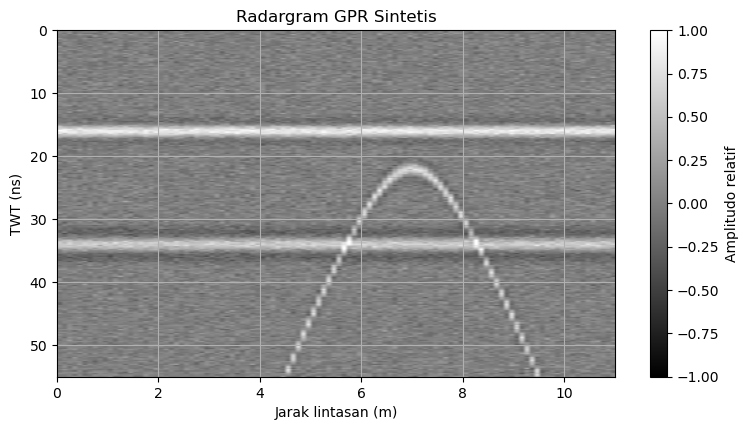

TWT=16.0 ns -> kedalaman ilustratif 0.80 m (v=0.10 m/ns)
TWT=34.0 ns -> kedalaman ilustratif 1.70 m (v=0.10 m/ns)
TWT=22.0 ns -> kedalaman ilustratif 1.10 m (v=0.10 m/ns)


In [4]:
n_trace, n_sample = 110, 260
x_gpr = np.linspace(0, 11, n_trace)
t_ns = np.linspace(0, 55, n_sample)
XX, TT = np.meshgrid(x_gpr, t_ns)
radar = np.random.normal(0, 0.08, (n_sample, n_trace))

for t_ref, amp, width in [(16, 0.85, 1.0), (34, 0.6, 1.5)]:
    radar += amp * np.exp(-0.5*((TT-t_ref)/width)**2) * np.cos(2*np.pi*(TT-t_ref)/4.8)

# Respons hiperbolik ilustratif
x0, t0 = 7.0, 22.0
t_curve = np.sqrt(t0**2 + (2*(XX-x0)/0.10)**2)
radar += 0.7 * np.exp(-0.5*((TT-t_curve)/1.0)**2) * np.cos(2*np.pi*(TT-t_curve)/4.5)

v_assumed = 0.10  # m/ns, asumsi ilustratif
depths_ref = v_assumed * np.array([16, 34, t0]) / 2

fig, ax = plt.subplots()
im = ax.imshow(radar, extent=[x_gpr.min(), x_gpr.max(), t_ns.max(), t_ns.min()],
               aspect="auto", cmap="gray", vmin=-1.0, vmax=1.0)
ax.set(title="Radargram GPR Sintetis", xlabel="Jarak lintasan (m)", ylabel="TWT (ns)")
fig.colorbar(im, ax=ax, label="Amplitudo relatif")
plt.show()

for twt, depth in zip([16, 34, t0], depths_ref):
    print(f"TWT={twt:.1f} ns -> kedalaman ilustratif {depth:.2f} m (v={v_assumed:.2f} m/ns)")

In [5]:
print("OUTPUT 2 | GPR")
print(f"Dengan asumsi v={v_assumed:.2f} m/ns, reflektor pada 16 ns dan 34 ns setara dengan {depths_ref[0]:.2f} m dan {depths_ref[1]:.2f} m.")
print(f"Puncak respons hiperbolik pada TWT {t0:.1f} ns setara dengan kedalaman sekitar {depths_ref[2]:.2f} m.")
print("Kedalaman ini bergantung pada kecepatan yang diasumsikan dan tidak mewakili pengukuran lapangan.")
print("QC:", "LULUS" if np.isfinite(radar).all() and (v_assumed > 0) else "PERIKSA DATA")

OUTPUT 2 | GPR
Dengan asumsi v=0.10 m/ns, reflektor pada 16 ns dan 34 ns setara dengan 0.80 m dan 1.70 m.
Puncak respons hiperbolik pada TWT 22.0 ns setara dengan kedalaman sekitar 1.10 m.
Kedalaman ini bergantung pada kecepatan yang diasumsikan dan tidak mewakili pengukuran lapangan.
QC: LULUS


# 5. Laboratorium Metode III — Seismologi
### Pertanyaan geofisika
Bagaimana rentang magnitudo dan kedalaman kejadian dalam sebuah katalog contoh?

#### Prompt RTCIK-OQV

| Elemen | Instruksi untuk AI |
|---|---|
| **R — Role** | Berperan sebagai seismolog yang memahami katalog kejadian dan distribusi hiposenter. |
| **T — Task** | Ringkas magnitudo dan kedalaman serta buat grafik waktu dan sebaran lokasi. |
| **C — Context** | Katalog dapat membantu menggambarkan aktivitas seismik; interpretasi tektonik perlu data nyata dan konteks regional. |
| **I — Input** | Waktu relatif, koordinat, kedalaman, dan magnitudo. |
| **K — Constraints** | Data sintetis tidak boleh dipakai untuk menyatakan aktivitas sesar nyata atau memprediksi gempa. |
| **O — Output** | Statistik deskriptif dan dua visualisasi katalog. |
| **Q — Quality Criteria** | Statistik dihitung dari tabel yang sama dan satuan dicantumkan. |
| **V — Verification** | Periksa jumlah kejadian, nilai kosong, serta rentang magnitudo dan kedalaman. |

### Input dan pemrosesan

,hari,longitude,latitude,kedalaman_km,magnitudo
0,0.473914,119.630636,-4.932947,12.908018,1.498966
1,0.649515,119.998615,-5.296713,26.263481,1.137208
2,0.733707,119.973326,-5.126359,27.194186,1.146570
3,0.897830,119.855682,-5.141284,15.220383,1.325175
4,1.032858,119.662626,-4.907170,25.812539,1.098933


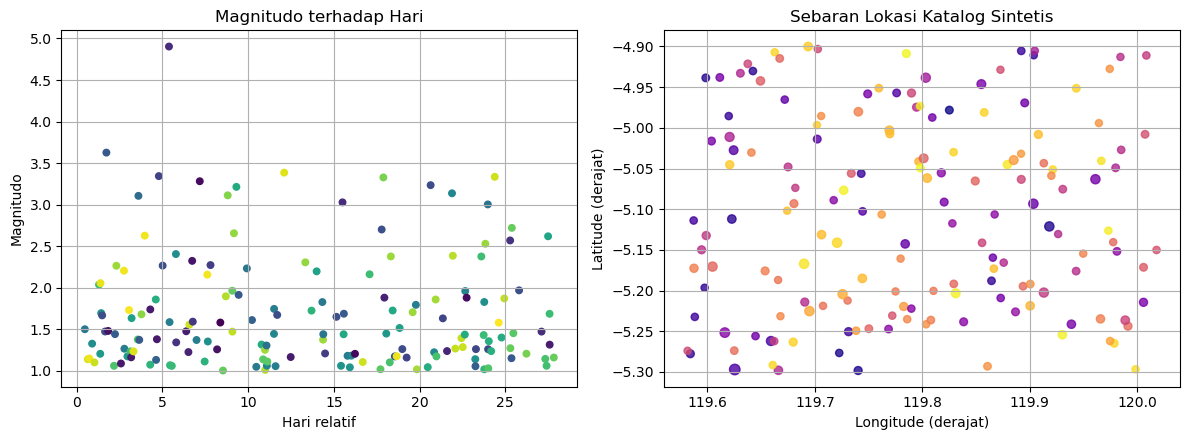

,magnitudo,kedalaman_km
count,160.00,160.00
mean,1.69,16.19
std,0.69,7.14
min,1.00,3.15
25%,1.18,9.93
50%,1.44,16.59
75%,1.92,22.06
max,4.90,27.85


In [6]:
n = 160
catalog = pd.DataFrame({
    "hari": np.sort(np.random.uniform(0, 28, n)),
    "longitude": 119.8 + np.random.uniform(-0.22, 0.22, n),
    "latitude": -5.1 + np.random.uniform(-0.20, 0.20, n),
    "kedalaman_km": np.random.uniform(3, 28, n),
    "magnitudo": np.clip(1.0 + np.random.exponential(0.7, n), 1.0, 5.0)
})
display(catalog.head())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(catalog["hari"], catalog["magnitudo"], c=catalog["kedalaman_km"], cmap="viridis", s=22)
axes[0].set(title="Magnitudo terhadap Hari", xlabel="Hari relatif", ylabel="Magnitudo")
axes[1].scatter(catalog["longitude"], catalog["latitude"], c=catalog["kedalaman_km"],
                s=18 + 8*catalog["magnitudo"], cmap="plasma", alpha=0.8)
axes[1].set(title="Sebaran Lokasi Katalog Sintetis", xlabel="Longitude (derajat)", ylabel="Latitude (derajat)")
plt.tight_layout()
plt.show()

display(catalog[["magnitudo", "kedalaman_km"]].describe().round(2))

In [7]:
print("OUTPUT 3 | SEISMOLOGI")
print(f"Jumlah kejadian: {len(catalog)}")
print(f"Magnitudo: {catalog.magnitudo.min():.2f}–{catalog.magnitudo.max():.2f}; rata-rata {catalog.magnitudo.mean():.2f}.")
print(f"Kedalaman: {catalog.kedalaman_km.min():.2f}–{catalog.kedalaman_km.max():.2f} km.")
print("Katalog hanya dibuat untuk latihan statistik; tidak mendukung kesimpulan tektonik wilayah nyata.")
print("QC:", "LULUS" if not catalog.isna().any().any() else "PERIKSA DATA")

OUTPUT 3 | SEISMOLOGI
Jumlah kejadian: 160
Magnitudo: 1.00–4.90; rata-rata 1.69.
Kedalaman: 3.15–27.85 km.
Katalog hanya dibuat untuk latihan statistik; tidak mendukung kesimpulan tektonik wilayah nyata.
QC: LULUS


# 6. Laboratorium Metode IV — Magnetotellurik (MT)
### Pertanyaan geofisika
Bagaimana resistivitas semu berubah terhadap periode pada kurva MT ilustratif?

#### Prompt RTCIK-OQV

| Elemen | Instruksi untuk AI |
|---|---|
| **R — Role** | Berperan sebagai geofisikawan MT yang memahami respons elektromagnetik bumi. |
| **T — Task** | Plot resistivitas semu terhadap periode dan uraikan tren utamanya. |
| **C — Context** | Respons MT dipengaruhi distribusi resistivitas; periode panjang umumnya memiliki sensitivitas lebih besar terhadap struktur dalam. |
| **I — Input** | Periode (s) dan resistivitas semu (Ω m). |
| **K — Constraints** | Tidak boleh mengklaim inversi atau kedalaman lapisan jika tidak dihitung. |
| **O — Output** | Kurva log-log, statistik nilai, dan interpretasi tren kualitatif. |
| **Q — Quality Criteria** | Periode serta resistivitas positif; sumbu dan satuan benar. |
| **V — Verification** | Periksa rentang data dan bedakan kurva observasi dari model bawah permukaan. |

### Input dan pemrosesan

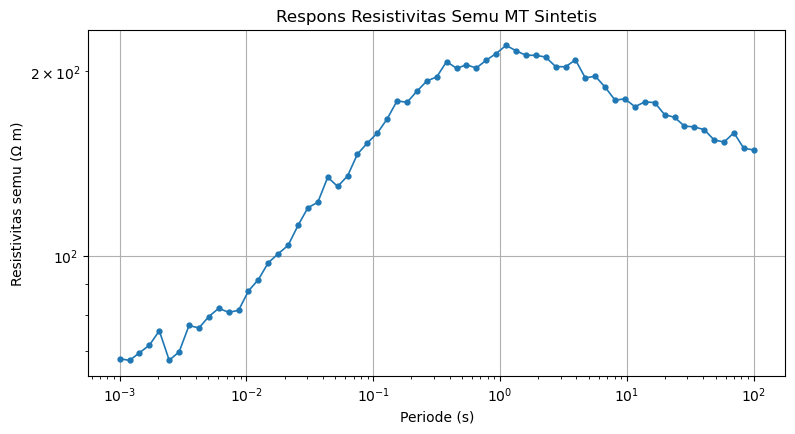

Minimum rho_a: 67.57 Ω m
Maksimum rho_a: 220.43 Ω m
Median rho_a: 160.62 Ω m


In [8]:
period = np.logspace(-3, 2, 65)
lp = np.log10(period)
rho = 65 + 190/(1 + np.exp(-(lp+1.0)*2.0)) - 105/(1 + np.exp(-(lp-0.7)*2.2))
rho += np.random.normal(0, 3.5, len(period))
rho = np.clip(rho, 5, None)

fig, ax = plt.subplots()
ax.loglog(period, rho, "o-", ms=3.5, lw=1.2)
ax.set(title="Respons Resistivitas Semu MT Sintetis", xlabel="Periode (s)", ylabel="Resistivitas semu (Ω m)")
plt.show()

print(f"Minimum rho_a: {rho.min():.2f} Ω m")
print(f"Maksimum rho_a: {rho.max():.2f} Ω m")
print(f"Median rho_a: {np.median(rho):.2f} Ω m")

In [9]:
print("OUTPUT 4 | MAGNETOTELLURIK")
print(f"Resistivitas semu berada pada rentang {rho.min():.1f}–{rho.max():.1f} Ω m.")
print("Kurva memperlihatkan perubahan respons listrik terhadap periode.")
print("Interpretasi lapisan dan kedalaman membutuhkan komponen impedansi, analisis dimensional, serta inversi yang sesuai.")
print("QC:", "LULUS" if np.isfinite(rho).all() and (period > 0).all() and (rho > 0).all() else "PERIKSA DATA")

OUTPUT 4 | MAGNETOTELLURIK
Resistivitas semu berada pada rentang 67.6–220.4 Ω m.
Kurva memperlihatkan perubahan respons listrik terhadap periode.
Interpretasi lapisan dan kedalaman membutuhkan komponen impedansi, analisis dimensional, serta inversi yang sesuai.
QC: LULUS


# 7. Laboratorium Metode V — Mikrotremor HVSR
### Pertanyaan geofisika
Berapa frekuensi pada puncak rasio H/V pada kurva ilustratif?

#### Prompt RTCIK-OQV

| Elemen | Instruksi untuk AI |
|---|---|
| **R — Role** | Berperan sebagai geofisikawan seismologi lingkungan yang memahami analisis HVSR. |
| **T — Task** | Temukan puncak kurva H/V dan laporkan frekuensi serta amplitudonya. |
| **C — Context** | Puncak H/V dapat membantu mengindikasikan frekuensi dominan tapak, tetapi perlu evaluasi kualitas dan konteks geologi. |
| **I — Input** | Frekuensi (Hz) dan rasio H/V sintetis. |
| **K — Constraints** | Jangan menyebut nilai sebagai hasil pengukuran; jangan menghitung ketebalan tanpa model Vs. |
| **O — Output** | Kurva H/V, frekuensi puncak, amplitudo puncak, dan catatan keterbatasan. |
| **Q — Quality Criteria** | Frekuensi positif, sumbu log sesuai, dan puncak diambil dari data yang diplot. |
| **V — Verification** | Pastikan posisi puncak benar dan interpretasi tidak melampaui data. |

### Input dan pemrosesan

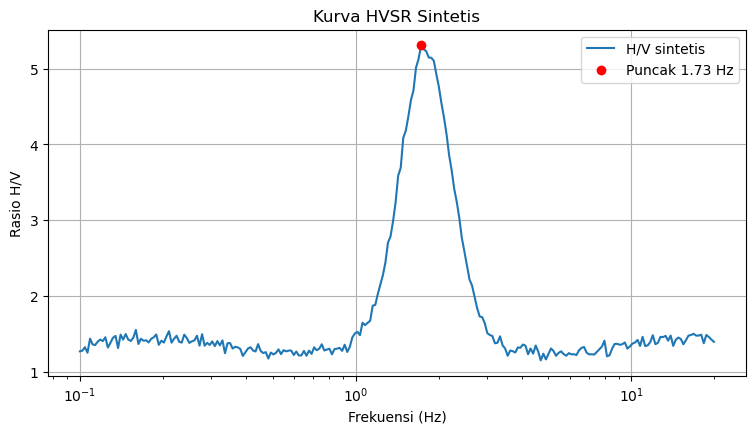

Frekuensi puncak: 1.729 Hz
Amplitudo puncak: 5.31


In [10]:
freq = np.logspace(-1, 1.3, 250)
hv = 1.35 + 3.8*np.exp(-0.5*((np.log(freq)-np.log(1.8))/0.21)**2)
hv += 0.10*np.sin(2.8*np.log(freq)) + np.random.normal(0, 0.05, len(freq))
hv = np.clip(hv, 0.5, None)
i_peak = int(np.argmax(hv))
f_peak, a_peak = float(freq[i_peak]), float(hv[i_peak])

fig, ax = plt.subplots()
ax.semilogx(freq, hv, lw=1.5, label="H/V sintetis")
ax.scatter([f_peak], [a_peak], color="red", zorder=3, label=f"Puncak {f_peak:.2f} Hz")
ax.set(title="Kurva HVSR Sintetis", xlabel="Frekuensi (Hz)", ylabel="Rasio H/V")
ax.legend()
plt.show()

print(f"Frekuensi puncak: {f_peak:.3f} Hz")
print(f"Amplitudo puncak: {a_peak:.2f}")

In [11]:
print("OUTPUT 5 | HVSR")
print(f"Puncak kurva sintetis berada pada {f_peak:.2f} Hz dengan rasio H/V {a_peak:.2f}.")
print("Puncak ini hanya menggambarkan model ilustratif dan bukan hasil rekaman mikrotremor lapangan.")
print("Estimasi ketebalan sedimen memerlukan kecepatan gelombang geser (Vs) dan asumsi model lapisan.")
print("QC:", "LULUS" if np.isfinite(hv).all() and (freq > 0).all() and (hv > 0).all() else "PERIKSA DATA")

OUTPUT 5 | HVSR
Puncak kurva sintetis berada pada 1.73 Hz dengan rasio H/V 5.31.
Puncak ini hanya menggambarkan model ilustratif dan bukan hasil rekaman mikrotremor lapangan.
Estimasi ketebalan sedimen memerlukan kecepatan gelombang geser (Vs) dan asumsi model lapisan.
QC: LULUS


## 8. Sintesis Lintas Metode

Kelima metode tidak mengukur besaran fisis yang sama. Oleh karena itu, output dibandingkan berdasarkan parameter yang diukur, produk analisis, dan batas interpretasinya — bukan dengan menyamakan nilai antar-metode.

In [12]:
ringkasan = pd.DataFrame([
    ["Geomagnetik", "Anomali medan magnet (nT)", "Peta anomali dan pusat nilai ekstrem", "Sumber magnetik tidak unik"],
    ["GPR", "Amplitudo dan TWT", "Radargram dan kedalaman berbasis kecepatan asumsi", "Kedalaman bergantung kecepatan rambat"],
    ["Seismologi", "Magnitudo, kedalaman, lokasi, waktu", "Statistik dan sebaran katalog", "Data sintetis bukan katalog kejadian nyata"],
    ["MT", "Resistivitas semu (Ω m) terhadap periode", "Kurva log-log", "Model kedalaman perlu inversi"],
    ["HVSR", "Rasio H/V terhadap frekuensi", "Frekuensi dan amplitudo puncak", "Ketebalan perlu model Vs"],
], columns=["Metode", "Parameter", "Output utama", "Batas interpretasi"])
display(ringkasan)

,Metode,Parameter,Output utama,Batas interpretasi
0,Geomagnetik,Anomali medan magnet (nT),Peta anomali dan pusat nilai ekstrem,Sumber magnetik tidak unik
1,GPR,Amplitudo dan TWT,Radargram dan kedalaman berbasis kecepatan asumsi,Kedalaman bergantung kecepatan rambat
2,Seismologi,"Magnitudo, kedalaman, lokasi, waktu",Statistik dan sebaran katalog,Data sintetis bukan katalog kejadian nyata
3,MT,Resistivitas semu (Ω m) terhadap periode,Kurva log-log,Model kedalaman perlu inversi
4,HVSR,Rasio H/V terhadap frekuensi,Frekuensi dan amplitudo puncak,Ketebalan perlu model Vs


## 9. Kesimpulan

Kerangka RTCIK-OQV membantu merumuskan prompt yang memiliki tugas, data masukan, batasan, bentuk keluaran, kriteria mutu, dan langkah verifikasi yang eksplisit. Dalam notebook ini, tiap metode menghasilkan satu output utama:

1. **Geomagnetik:** peta anomali dan posisi nilai ekstrem.
2. **GPR:** radargram dan estimasi kedalaman berdasarkan kecepatan asumsi.
3. **Seismologi:** statistik katalog dan visualisasi sebaran.
4. **MT:** kurva resistivitas semu terhadap periode.
5. **HVSR:** frekuensi dan amplitudo puncak kurva H/V.

Semua hasil numerik adalah demonstrasi dari data sintetis. Hasil tersebut tidak boleh diperlakukan sebagai temuan lapangan. Untuk analisis nyata, ganti input sintetis dengan data lapangan atau dataset terbuka dan dokumentasikan proses pengunduhan, prapemrosesan, serta asumsi yang digunakan.

## 10. Sumber Data dan Referensi untuk Pengembangan

Tautan ini adalah pintu masuk untuk memperoleh data atau pedoman nyata. Dataset yang dipilih harus sesuai dengan wilayah, metode, format, dan metadata yang tersedia. Nilai yang dihitung di notebook ini **tidak berasal dari tautan berikut**.

1. **Geomagnetik — USGS:** https://www.usgs.gov/ (cari “aeromagnetic data” atau “magnetic anomaly data”).
2. **GPR — USGS Long Beach Island:** https://pubs.usgs.gov/ds/1006/ds1006_data.html
3. **Seismologi — USGS Earthquake Catalog:** https://earthquake.usgs.gov/earthquakes/search/
4. **Magnetotellurik — USGS:** https://www.usgs.gov/ (cari “magnetotelluric data”).
5. **HVSR — SESAME Project:** https://sesame.geopsy.org/

### Catatan reproducibility

- Jalankan sel secara berurutan dari atas ke bawah.
- Data sintetis dapat berubah jika seed acak diubah.
- Jangan menyebut hasil sintetis sebagai data lapangan.
- Untuk hasil berbasis data nyata, catat nama dataset, lembaga penyedia, tanggal akses, sistem koordinat, satuan, dan tahapan prapemrosesan.